# Multiple Regression Analysis

This analysis examines whether model choice and request/input type are associated with model response time and whether the relationship between input type and response time differs across models.

## Research Objective

The primary outcome of interest is `model_time_seconds`, which represents the response time for each successful model call.

The analysis focuses on two categorical predictors: `model` and `input_type`. The objective is to determine whether response time differs across models and request types when both factors are considered simultaneously, and whether the relationship between request type and response time depends on the model being used.

The results will be used to compare candidate regression models and support selection of the final model for the team project.

## Hypotheses

### Main Effects

**Null hypothesis (H0):** Model choice and input type are not associated with model response time.

**Alternative hypothesis (HA):** At least one model or input-type effect is associated with model response time.


### Interaction Effect

**Null hypothesis (H0):** There is no interaction between model and input type; the relationship between input type and response time is the same across models.

**Alternative hypothesis (HA):** There is an interaction between model and input type; the relationship between input type and response time differs across models.

## Data Preparation

In [30]:
# import libraries
import math
import numpy as np
import pandas as pd
from scipy import stats

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.diagnostic import het_breuschpagan

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [2]:
df = pd.read_csv("../cleanup/Olena_Log_Template_Proposed.csv")
# Preview selected variables used in the analysis.

df[
    [
        "test_id",
        "scenario_name",
        "input_type",
        "model",
        "model_time_seconds",
        "gpu_avg_pct",
        "workflow_time_seconds",
        "success"
    ]
].head()

,test_id,scenario_name,input_type,model,model_time_seconds,gpu_avg_pct,workflow_time_seconds,success
0,1,Text Input - Model A,Text Only,minicpm-o-2_6,5.0,3.60,33.0,Yes
1,2,Text Input - Model B,Text Only,gemma-3-12b-it,17.0,2.53,33.0,Yes
2,3,Text Input - Model C,Text Only,pixtral-12b,8.0,2.25,33.0,Yes
3,4,Text Input - Model D,Text Only,qwen2-vl-7b-instruct,4.0,4.20,33.0,Yes
4,5,Text+Image Input - Model A,Text + Image,minicpm-o-2_6,10.0,9.90,116.0,Yes


In [15]:
# Keep only successful model runs.
# Failed or not-executed requests do not have valid response-time measurements,
# so they should not be included in the response-time analysis

df_success = df[df["success"] == "Yes"].copy()

# Check the size of the filtered dataset, missing values, data types. etc.
print (df_success.shape)
print (df_success[["input_type", "model", "model_time_seconds"]].dtypes)

print (df_success[["input_type", "model", "model_time_seconds"]].isna().sum())

print (df_success["model"].value_counts())
print (df_success["input_type"].value_counts())

print (df_success["model"].unique())
print (df_success["input_type"].unique())




(460, 30)
input_type                str
model                     str
model_time_seconds    float64
dtype: object
input_type            0
model                 0
model_time_seconds    0
dtype: int64
model
minicpm-o-2_6           115
gemma-3-12b-it          115
pixtral-12b             115
qwen2-vl-7b-instruct    115
Name: count, dtype: int64
input_type
Mixed           312
Text Only       116
Text + Image     16
Image Only       16
Name: count, dtype: int64
<StringArray>
['minicpm-o-2_6', 'gemma-3-12b-it', 'pixtral-12b', 'qwen2-vl-7b-instruct']
Length: 4, dtype: str
<StringArray>
['Text Only', 'Text + Image', 'Image Only', 'Mixed']
Length: 4, dtype: str


## Candidate Model 1: Additive Multiple Regression

The first candidate model evaluates the main effects of model choice and input type on response time without including an interaction between the two predictors.

In [17]:
# multiole logistic regression
model_1 = smf.ols(
    formula="model_time_seconds ~ C(model) + C(input_type)",
    data=df_success
)
# model train
model_1_fit = model_1.fit()

# display results
print(model_1_fit.summary())

                            OLS Regression Results                            
Dep. Variable:     model_time_seconds   R-squared:                       0.344
Model:                            OLS   Adj. R-squared:                  0.335
Method:                 Least Squares   F-statistic:                     39.52
Date:                Thu, 08 Oct 2026   Prob (F-statistic):           1.22e-38
Time:                        20:24:51   Log-Likelihood:                -2261.7
No. Observations:                 460   AIC:                             4537.
Df Residuals:                     453   BIC:                             4566.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
Intercep

In [ ]:
# check distribution input_type inside every model
pd.crosstab(df_success["model"], df_success["input_type"])

input_type,Image Only,Mixed,Text + Image,Text Only
model,,,,
gemma-3-12b-it,4,78,4,29
minicpm-o-2_6,4,78,4,29
pixtral-12b,4,78,4,29
qwen2-vl-7b-instruct,4,78,4,29


In [ ]:
# test whether model and input type have significant overall effects on responce time
anova_lm(model_1_fit, typ=2)

,sum_sq,df,F,PR(>F)
C(model),257878.486957,3.0,77.520528,1.735869e-40
C(input_type),5041.306548,3.0,1.515461,2.097442e-01
Residual,502314.067365,453.0,NaN,NaN


### Candidate Model 1 Results

The additive multiple regression model was statistically significant overall, F(6, 453) = 39.52, p < .001, and explained approximately 34.4% of the variation in model response time (R² = 0.344; adjusted R² = 0.335). Model choice showed a statistically significant overall association with response time, F(3, 453) = 77.52, p < .001. Compared with Gemma, MiniCPM, Pixtral, and Qwen all had significantly shorter estimated response times (p < .001). In contrast, input type was not statistically significant as an overall factor after accounting for model choice, F(3, 453) = 1.52, p = .210. These results suggest that model choice is a substantially stronger predictor of response time than input type in the additive model.

## Candidate Model 2: Interaction Model

The second candidate model adds an interaction between model and input type to evaluate whether the relationship between request type and response time differs across models.

In [ ]:
# fit a multiple regression model including the interaction
# between model choice and input type.

model_2 = smf.ols(
    formula="model_time_seconds ~ C(model) * C(input_type)",
    data=df_success
)

model_2_fit = model_2.fit()

print(model_2_fit.summary())

                            OLS Regression Results                            
Dep. Variable:     model_time_seconds   R-squared:                       0.355
Model:                            OLS   Adj. R-squared:                  0.333
Method:                 Least Squares   F-statistic:                     16.30
Date:                Thu, 08 Oct 2026   Prob (F-statistic):           6.86e-34
Time:                        20:40:29   Log-Likelihood:                -2257.7
No. Observations:                 460   AIC:                             4547.
Df Residuals:                     444   BIC:                             4613.
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
                                                                     coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------

In [ ]:
# compare the additive and interaction models to test whether
# the interaction terms significantly improve model fit.

anova_lm(model_1_fit, model_2_fit)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,453.0,502314.067365,0.0,NaN,NaN,NaN
1,444.0,493510.870248,9.0,8803.197117,0.880003,0.54305


### Candidate Model 2 Results

The interaction model was statistically significant overall, F(15, 444) = 16.30, p < .001, and explained approximately 35.5% of the variation in model response time (R² = 0.355; adjusted R² = 0.333). Although the interaction model produced a slightly higher R² than the additive model, the adjusted R² decreased, suggesting that the additional interaction terms did not provide sufficient explanatory improvement relative to the increased model complexity.

## Model Comparison

The candidate models are compared to determine whether the additional interaction terms provide meaningful improvement in model fit and interpretation relative to the simpler additive model.

A nested-model F-test was used to compare the additive model with the interaction model. Adding the model × input type interaction did not significantly improve model fit, F(9, 444) = 0.88, p = .543. Therefore, the null hypothesis that the interaction terms do not improve the model was not rejected.
The additive model was retained as the preferred candidate because it provides a more parsimonious explanation of response-time variation without a meaningful loss of explanatory performance. The interaction model increased R² only slightly, from 0.344 to 0.355, while adjusted R² decreased from 0.335 to 0.333.

## Regression Diagnostics

Regression assumptions and residual behavior are evaluated before selecting the final model. Particular attention is given to the distribution of residuals, constant variance, and unusually influential observations because the exploratory analysis identified right-skewed response-time distributions and several large response-time values.

The preferred additive regression model is evaluated using residual diagnostics before final model selection. The analysis focuses on residual patterns, normality, constant variance, and potentially influential observations.

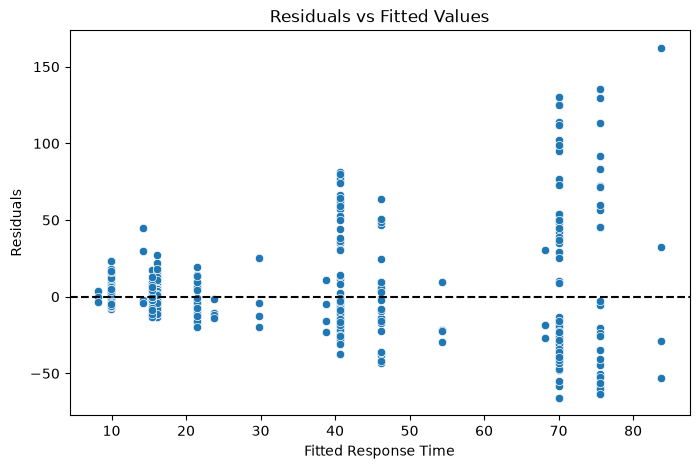

In [ ]:
# store fitted values and residuals from the additive regression model.
fitted_values = model_1_fit.fittedvalues
residuals = model_1_fit.resid

# plot residuals against fitted values.
plt.figure(figsize=(8, 5))
sns.scatterplot(x=fitted_values, y=residuals)

plt.axhline(y=0, color="black", linestyle="--")
plt.xlabel("Fitted Response Time")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted Values")
plt.show()

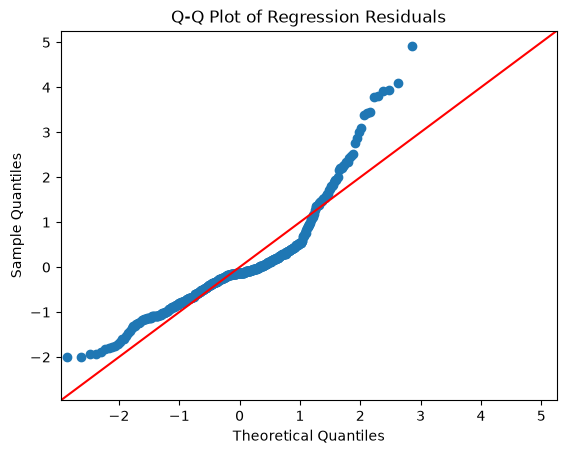

In [ ]:
# check whether the regression residuals are approximately normally distributed.
sm.qqplot(residuals, line="45", fit=True)

plt.title("Q-Q Plot of Regression Residuals")
plt.show()

### Diagnostic Results

The residuals-versus-fitted plot shows substantially greater residual variability at higher fitted response times, suggesting non-constant variance. Because the predictors are categorical, the fitted values appear in vertical groups, which is expected. However, the spread of the residuals is not consistent across those groups.

The Q-Q plot also shows substantial deviation from the reference line, particularly in the upper tail, indicating that the residuals are strongly right-skewed and do not closely follow a normal distribution. These diagnostic results suggest that a transformation of response time should be evaluated before selecting the final model.

## Candidate Model 3: Log-Transformed Response Time

Because the additive model showed right-skewed residuals and non-constant variance, a log transformation of model response time was evaluated. The predictor structure remains unchanged so that the transformed model can be assessed as an alternative specification of the preferred additive model.

In [ ]:
# create a log-transformed response-time variable.
df_success["log_model_time_seconds"] = np.log(
    df_success["model_time_seconds"]
)

# fit the additive regression model using log-transformed response time.
model_3 = smf.ols(
    formula="log_model_time_seconds ~ C(model) + C(input_type)",
    data=df_success
)

model_3_fit = model_3.fit()

print(model_3_fit.summary())

                              OLS Regression Results                              
Dep. Variable:     log_model_time_seconds   R-squared:                       0.446
Model:                                OLS   Adj. R-squared:                  0.439
Method:                     Least Squares   F-statistic:                     60.76
Date:                    Thu, 08 Oct 2026   Prob (F-statistic):           4.34e-55
Time:                            20:55:25   Log-Likelihood:                -523.34
No. Observations:                     460   AIC:                             1061.
Df Residuals:                         453   BIC:                             1090.
Df Model:                               6                                         
Covariance Type:                nonrobust                                         
                                       coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------

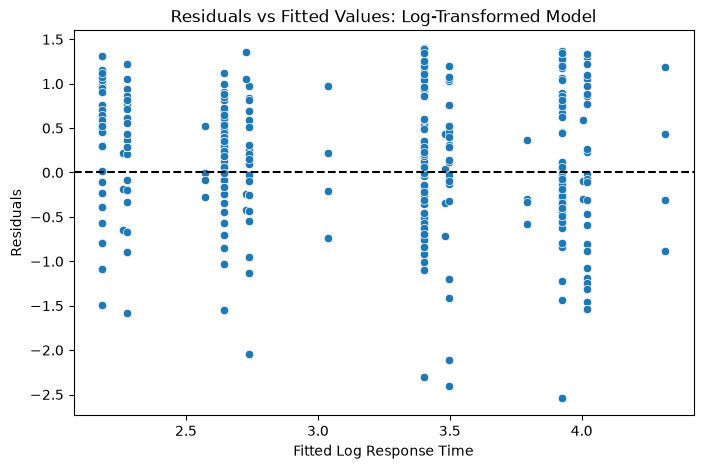

In [ ]:
# store fitted values and residuals from the log-transformed model.
log_fitted_values = model_3_fit.fittedvalues
log_residuals = model_3_fit.resid

# plot residuals against fitted values.
plt.figure(figsize=(8, 5))
sns.scatterplot(x=log_fitted_values, y=log_residuals)

plt.axhline(y=0, color="black", linestyle="--")
plt.xlabel("Fitted Log Response Time")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted Values: Log-Transformed Model")
plt.show()

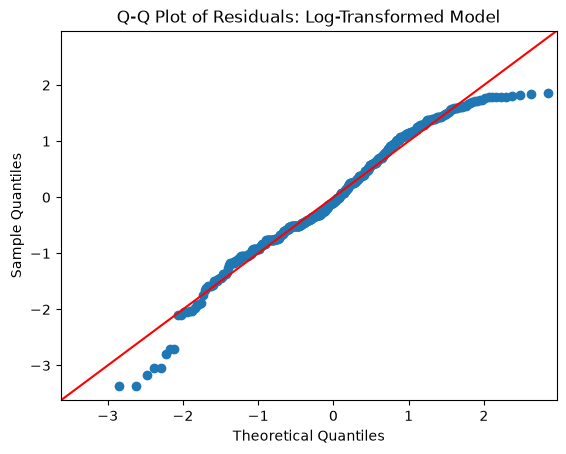

In [ ]:
# check normality of residuals for the log-transformed model.
sm.qqplot(log_residuals, line="45", fit=True)

plt.title("Q-Q Plot of Residuals: Log-Transformed Model")
plt.show()

### Candidate Model 3 Results

The log-transformed additive regression model was statistically significant overall, F(6, 453) = 60.76, p < .001, and explained 44.6% of the variation in log-transformed response time (R² = 0.446; adjusted R² = 0.439). Model choice remained strongly associated with response time, with MiniCPM, Pixtral, and Qwen all showing significantly lower log response times than Gemma (p < .001). Input type remained non-significant after accounting for model choice.

The residual diagnostics improved substantially after log transformation. The residuals-versus-fitted plot showed a more consistent spread across fitted values, while the Q-Q plot showed much closer agreement with the reference line than the raw-response model. Some deviations remained in the tails, but the transformation substantially reduced the strong right-skew observed in the original model.

In [ ]:
# test for heteroscedasticity in the log-transformed model.
bp_test = het_breuschpagan(
    model_3_fit.resid,
    model_3_fit.model.exog
)

bp_labels = ["LM Statistic", "LM p-value", "F Statistic", "F p-value"]

print(dict(zip(bp_labels, bp_test)))

{'LM Statistic': np.float64(17.101481986999378), 'LM p-value': np.float64(0.008917430486914606), 'F Statistic': np.float64(2.9152544826997), 'F p-value': np.float64(0.00844823676687574)}


### Heteroscedasticity Test

The Breusch-Pagan test was statistically significant (p < .01), indicating that some heteroscedasticity remained in the log-transformed model. Therefore, HC3 heteroscedasticity-robust standard errors were used for the final statistical inference.

In [32]:
# Use HC3 robust standard errors to account for remaining heteroscedasticity.
model_3_robust = model_3_fit.get_robustcov_results(cov_type="HC3")

print(model_3_robust.summary())

                              OLS Regression Results                              
Dep. Variable:     log_model_time_seconds   R-squared:                       0.446
Model:                                OLS   Adj. R-squared:                  0.439
Method:                     Least Squares   F-statistic:                     60.23
Date:                    Thu, 08 Oct 2026   Prob (F-statistic):           1.05e-54
Time:                            21:03:37   Log-Likelihood:                -523.34
No. Observations:                     460   AIC:                             1061.
Df Residuals:                         453   BIC:                             1090.
Df Model:                               6                                         
Covariance Type:                      HC3                                         
                                       coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------

## Final Model Selection

The final model is selected based on statistical performance, regression diagnostics, model complexity, and interpretability in relation to the project research question.

The log-transformed additive multiple regression model with HC3 robust standard errors was selected as the preferred model.

The original additive model showed substantial right-skew in the residuals and evidence of non-constant variance. Adding a model × input type interaction did not significantly improve model fit, F(9, 444) = 0.88, p = .543, so the simpler additive structure was retained.

Log-transforming response time substantially improved the residual distribution and reduced skewness. Because the Breusch-Pagan test still indicated remaining heteroscedasticity (p < .01), HC3 robust standard errors were used for the final statistical inference.

In the final model, model choice remained strongly associated with response time, while input type was not statistically significant after accounting for model choice. The final model explained approximately 44.6% of the variation in log-transformed response time (R² = 0.446; adjusted R² = 0.439).

## Final Model Interpretation and Conclusions

The final selected model was a log-transformed additive multiple regression with HC3 robust standard errors. The model evaluated the association of model choice and input type with response time using 460 successful model runs.

Model choice was the primary factor associated with response time. Using Gemma as the reference model, MiniCPM, Pixtral, and Qwen all had significantly lower response times (p < .001). After converting the log-scale coefficients to approximate percentage differences, MiniCPM response time was about 72% lower than Gemma, Pixtral about 41% lower, and Qwen about 83% lower, holding input type constant.

In contrast, input type was not statistically significant after accounting for model choice. Mixed, Text + Image, and Text Only requests did not show statistically significant differences from the Image Only reference category in the final model. The interaction between model and input type was also not significant, indicating that there was not sufficient evidence that the effect of input type on response time differed across models.

The interaction model did not significantly improve fit compared with the simpler additive model, so the additive structure was retained. A log transformation was used because the original response-time model showed strongly right-skewed residuals and non-constant variance. The transformation substantially improved the residual distribution, and HC3 robust standard errors were used because some heteroscedasticity remained.

Overall, the results suggest that model selection is considerably more important for response-time performance than request input type in this dataset. Among the four models, Qwen showed the largest reduction in response time relative to Gemma, followed by MiniCPM and Pixtral. These findings support using model choice as a primary consideration when optimizing response time in a multi-model workflow.